Silhouette Score DBSCAN (Abaikan Noise): 0.3680
Jumlah Cluster Terbentuk : 3
Jumlah Titik Noise (-1)  : 12


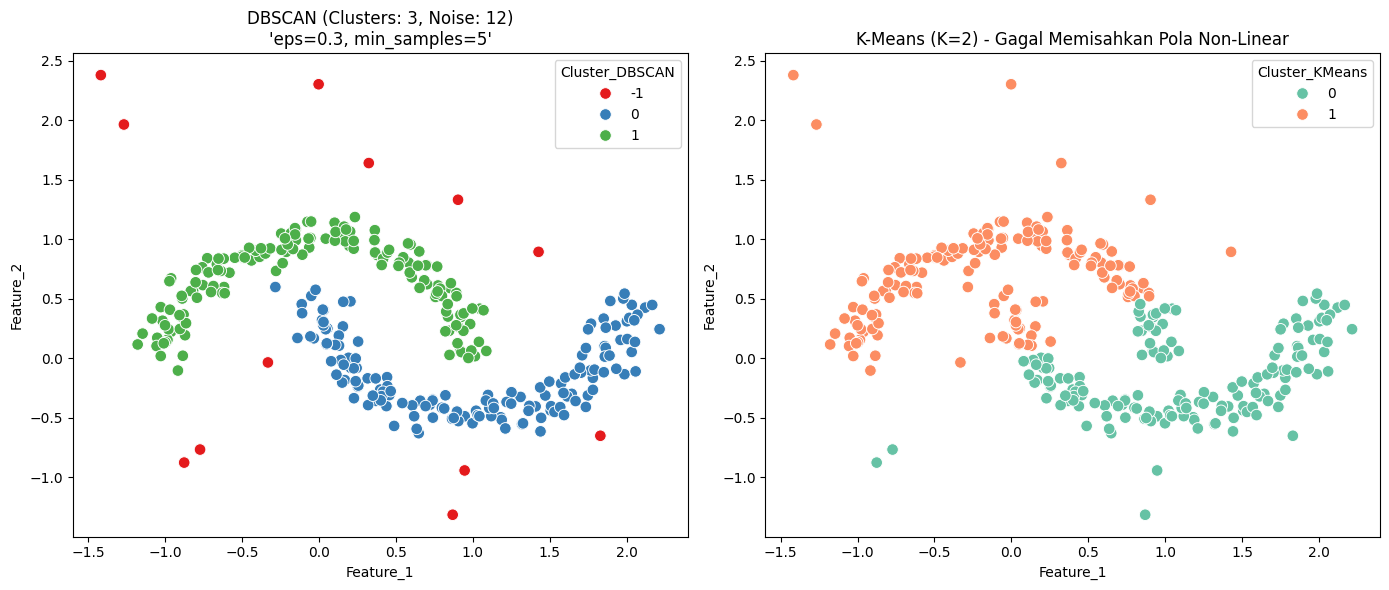

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import DBSCAN, KMeans
from sklearn.datasets import make_moons
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# 1. BUAT DATASET SINTETIS DENGAN NOISE
# Dataset berbentuk 2 bulan sabit (sulit ditangani K-Means)
X, y_true = make_moons(n_samples=300, noise=0.08, random_state=42)

# Tambahkan beberapa titik noise buatan secara acak
np.random.seed(42)
noise_points = np.random.uniform(low=-1.5, high=2.5, size=(15, 2))
X = np.vstack([X, noise_points])

# Convert ke DataFrame
df = pd.DataFrame(X, columns=["Feature_1", "Feature_2"])


# 2. PREPROCESSING / FEATURE SCALING
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)


# 3. TRAINING MODEL DBSCAN
# eps = jarak radius tetangga, min_samples = minimal tetangga
dbscan = DBSCAN(eps=0.3, min_samples=5)
df["Cluster_DBSCAN"] = dbscan.fit_predict(X_scaled)


# 4. TRAINING K-MEANS SEBAGAI PEMBANDING
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
df["Cluster_KMeans"] = kmeans.fit_predict(X_scaled)


# 5. EVALUASI MODEL
# Filter out noise (-1) saat menghitung Silhouette Score untuk DBSCAN
non_noise_mask = df["Cluster_DBSCAN"] != -1
if len(set(df.loc[non_noise_mask, "Cluster_DBSCAN"])) > 1:
    sil_dbscan = silhouette_score(
        X_scaled[non_noise_mask], df.loc[non_noise_mask, "Cluster_DBSCAN"]
    )
    print(f"Silhouette Score DBSCAN (Abaikan Noise): {sil_dbscan:.4f}")

n_noise = (df["Cluster_DBSCAN"] == -1).sum()
n_clusters = len(set(df["Cluster_DBSCAN"])) - (1 if -1 in df["Cluster_DBSCAN"] else 0)
print(f"Jumlah Cluster Terbentuk : {n_clusters}")
print(f"Jumlah Titik Noise (-1)  : {n_noise}")


# 6. VISUALISASI PERBANDINGAN: DBSCAN VS K-MEANS
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

# Plot DBSCAN
sns.scatterplot(
    data=df,
    x="Feature_1",
    y="Feature_2",
    hue="Cluster_DBSCAN",
    palette="Set1",
    ax=ax[0],
    s=70,
)
ax[0].set_title(
    f"DBSCAN (Clusters: {n_clusters}, Noise: {n_noise})\n'eps=0.3, min_samples=5'"
)

# Plot K-Means
sns.scatterplot(
    data=df,
    x="Feature_1",
    y="Feature_2",
    hue="Cluster_KMeans",
    palette="Set2",
    ax=ax[1],
    s=70,
)
ax[1].set_title("K-Means (K=2) - Gagal Memisahkan Pola Non-Linear")

plt.tight_layout()
plt.show()

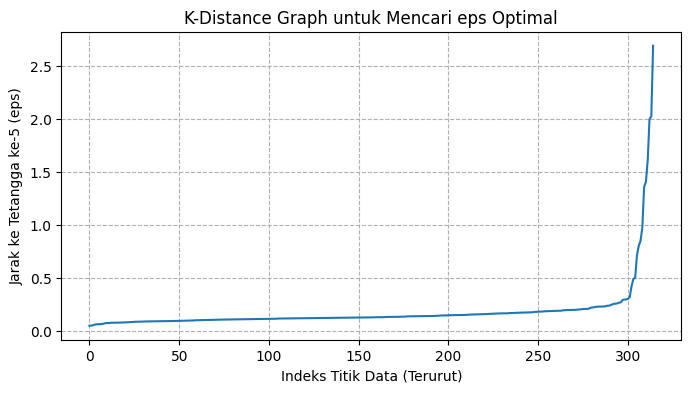

In [2]:
from sklearn.neighbors import NearestNeighbors

# Cari jarak ke tetangga ke-k (k = min_samples = 5)
neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)

# Urutkan jarak tetangga ke-5 dari terkecil ke terbesar
distances = np.sort(distances[:, 4], axis=0)

# Plot K-Distance Graph
plt.figure(figsize=(8, 4))
plt.plot(distances)
plt.title("K-Distance Graph untuk Mencari eps Optimal")
plt.xlabel("Indeks Titik Data (Terurut)")
plt.ylabel("Jarak ke Tetangga ke-5 (eps)")
plt.grid(True, linestyle="--")
plt.show()